# *Análise exploratória de Monitoramento de Fauna*

### •Importação das Bibliotecas

In [115]:
import pandas as pd
import numpy as np
from datetime import time
#%pip install matplotlib
#%pip install plotly
#%pip install jinja2
import matplotlib.pyplot as plt
import plotly as py
from numpy import var

### •Configuração para mostrar as linhas e colunas do arquivo

In [2]:
desired_width = 320
np.set_printoptions(linewidth=desired_width)
pd.set_option('display.width', desired_width)
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows', None)

### •Importação do Dataset

In [123]:
dt = pd.read_json("dataset_monitoramento_fauna.json")
display(dt.head().style.hide(axis='index'))#esconde o index já que existe a coluna de ID

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%


### •Informações gerais do Dataset

In [125]:
dt.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id_registro       5000 non-null   int64
 1   id_camera         5000 non-null   str  
 2   data_hora_inicio  5000 non-null   str  
 3   duracao_segundos  5000 non-null   int64
 4   especie           5000 non-null   str  
 5   grupo             5000 non-null   str  
 6   individuos        5000 non-null   int64
 7   temperatura_c     4753 non-null   str  
 8   umidade_pct       4825 non-null   str  
dtypes: int64(3), str(6)
memory usage: 351.7 KB


### •Mostrar primeiras e últimas linhas

In [122]:
display(pd.concat([dt.head(10), dt.iloc[-8:]]).style.hide(axis='index'))

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%
6,CAM08,2026-05-01 00:47:00,19,Sapo-cururu,Anfíbio,3,18.2 °C,90.9%
7,CAM12,2026-05-01 00:48:00,46,Quati,Mamífero,4,16.9 °C,95.5%
8,CAM05,2026-05-01 00:49:00,35,Perereca-verde,Anfíbio,2,14.6 °C,94.1%
9,CAM04,2026-05-01 00:49:00,46,Sapo-cururu,Anfíbio,3,20.6 °C,92.8%
10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%


### •Mostrar colunas com linhas em branco

In [127]:
colunas = dt.isnull().any()
print(colunas)

display(dt.columns[colunas])

id_registro         False
id_camera           False
data_hora_inicio    False
duracao_segundos    False
especie             False
grupo               False
individuos          False
temperatura_c        True
umidade_pct          True
dtype: bool


Index(['temperatura_c', 'umidade_pct'], dtype='str')

### •Qtd de linhas em branco

In [7]:
linhas = dt.columns[colunas]
dt[linhas].isnull().sum()


temperatura_c    247
umidade_pct      175
dtype: int64

### •Mostrar qtd de registros de cada espécie

In [24]:
dt[["id_registro","especie"]].groupby("especie").count().sort_values(by="id_registro",ascending=False)

,id_registro
especie,
Capivara,731
Sapo-cururu,564
Ema,551
Seriema,506
Lobo-guará,425
Tamanduá-bandeira,401
Perereca-verde,389
Quati,378
Rã-manteiga,317


### •Mostrar espécies únicas

In [9]:
dt.especie.unique()


<StringArray>
['Ema', 'Rã-manteiga', 'Tatu-canastra', 'Tamanduá-bandeira', 'Sapo-cururu', 'Quati', 'Perereca-verde', 'Capivara', 'Veado-campeiro', 'Lobo-guará', 'Seriema', 'Onça-pintada', 'Cervo-do-pantanal']
Length: 13, dtype: str

### •Mostrar qtd de registros por câmera

In [148]:
dt.id_camera.value_counts().reset_index()

,id_camera,count
0,CAM09,523
1,CAM12,504
2,CAM10,474
3,CAM02,471
4,CAM04,442
5,CAM08,418
6,CAM06,400
7,CAM01,394
8,CAM05,377
9,CAM07,364


### •Mostrar qtd de registros por câmera e epécie

In [144]:
resultado = (
    dt.value_counts(["id_camera", "especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["id_camera", "Qtd"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

resultado.head(30)

,id_camera,especie,Qtd
0,CAM01,Ema,80
1,CAM01,Seriema,76
2,CAM01,Lobo-guará,66
3,CAM01,Veado-campeiro,53
4,CAM01,Tamanduá-bandeira,35
5,CAM01,Tatu-canastra,32
6,CAM01,Sapo-cururu,14
7,CAM01,Quati,14
8,CAM01,Capivara,9
9,CAM01,Cervo-do-pantanal,7


### •Mostrar Qual epécie foi mais registrada

In [151]:
Qtd = (
    dt.value_counts(["especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["Qtd"],
        ascending=[False]
    ).reset_index(drop=True)
)

Qtd

,especie,Qtd
0,Capivara,731
1,Sapo-cururu,564
2,Ema,551
3,Seriema,506
4,Lobo-guará,425
5,Tamanduá-bandeira,401
6,Perereca-verde,389
7,Quati,378
8,Rã-manteiga,317
9,Veado-campeiro,292


## Desafio 1 - Animais solitários ou em grupo?

Durante o monitoramento, os pesquisadores querem entender como a **capivara** costuma ser registrada pelas câmeras.

**Pergunta:**

> **Qual é o número médio de indivíduos por registro de capivara? A maior parte dos registros envolve indivíduos isolados ou grupos?**

### •Mostrar registros da Capivara

In [12]:
capi = dt[(dt.especie=='Capivara')]
capi.head(10)


,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
9,10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%
22,23,CAM12,2026-05-01 03:06:00,37,Capivara,Mamífero,5,15.7 °C,98.6%
37,38,CAM09,2026-05-01 05:11:00,30,Capivara,Mamífero,11,18.3 °C,96.3%
45,46,CAM10,2026-05-01 06:04:00,4,Capivara,Mamífero,7,18.5 °C,88.0%
47,48,CAM12,2026-05-01 06:08:00,24,Capivara,Mamífero,3,17.7 °C,99.0%
49,50,CAM05,2026-05-01 06:31:00,53,Capivara,Mamífero,5,21.0 °C,91.7%
50,51,CAM09,2026-05-01 06:44:00,11,Capivara,Mamífero,6,18.2 °C,97.1%
55,56,CAM07,2026-05-01 07:13:00,16,Capivara,Mamífero,6,19.6 °C,84.1%
56,57,CAM07,2026-05-01 07:24:00,18,Capivara,Mamífero,6,17.5 °C,85.2%
62,63,CAM10,2026-05-01 08:01:00,6,Capivara,Mamífero,10,21.9 °C,94.9%


### *Número médio de indivíduos por registro:*

In [13]:
media = round(dt[(dt.especie=='Capivara')].individuos.mean(),2)
print("Média de indivíduos =", media)

Média de indivíduos = 5.95


### *Mostrar os registros de indivíduos solitários:*

In [92]:
capi_so_qtd = dt[(dt.especie=='Capivara') & 
                 (dt.individuos==1)
]['id_registro'].count()
capi_so = dt[(dt.especie=='Capivara') & 
             (dt.individuos==1)
][
    ['id_registro','individuos','data_hora_inicio']
]
print("Registros de Inivíduos Solitários =", capi_so_qtd)
display(capi_so)



Registros de Inivíduos Solitários = 6


,id_registro,individuos,data_hora_inicio
1973,1974,1,2026-05-12 18:15:00
2194,2195,1,2026-05-14 02:40:00
3972,3973,1,2026-05-24 17:04:00
4363,4364,1,2026-05-27 03:10:00
4556,4557,1,2026-05-28 07:20:00
4954,4955,1,2026-05-30 16:50:00


### *Mostrar os registros em grupo:*

In [110]:
capi_grp_qtd = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
    'id_registro'].count()

capi_grp = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
        ['id_registro','individuos','data_hora_inicio']
].sort_values(
    by='individuos', 
    ascending=False
).reset_index(drop=True)
print("Registros de Indivíduos em Grupos =", capi_grp_qtd)
display(capi_grp.head())


Registros de Indivíduos em Grupos = 725


,id_registro,individuos,data_hora_inicio
0,1068,14,2026-05-07 10:58:00
1,1648,14,2026-05-10 16:36:00
2,634,13,2026-05-04 19:31:00
3,936,13,2026-05-06 17:33:00
4,4943,13,2026-05-30 15:16:00


### Quantidade de Grupos encontrados

In [16]:
grupos = capi_grp['individuos'].value_counts().sort_index().reset_index()
grupos.columns = ['Individuos', 'Qtd_Registros']
display(grupos)

print("Total de grupos:", len(grupos))


,Individuos,Qtd_Registros
0,2,23
1,3,63
2,4,100
3,5,129
4,6,128
5,7,120
6,8,79
7,9,40
8,10,23
9,11,10


Total de grupos: 13


## Desafio 2 - Quando a fauna está mais ativa?

Depois de entender como os registros se distribuem entre as espécies, a equipe quer investigar **quando** os animais são mais frequentemente registrados.

**Pergunta:**

> **Em quais períodos do dia há mais registros de animais? Escolha três espécies e compare seus horários de maior ocorrência.**

### •Separar a coluna data_hora_inicio em Data e Hora

In [17]:
dt[['Data','Hora']] = dt['data_hora_inicio'].str.split(' ',n=1, expand=True)
dt['Hora'] = pd.to_datetime(dt['Hora'],format='%H:%M:%S').dt.time
dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00


### •Criação de uma coluna nova chamada Periodo, para facilitar a análise de acordo com o período do dia.

In [20]:
dt['Periodo'] = 'Manhã'

dt.loc[dt['Hora'].between(time(0, 0), time(5, 0)),'Periodo'] = 'Madrugada'
dt.loc[dt['Hora'].between(time(12, 0), time(18, 0)),'Periodo'] = 'Tarde'
dt.loc[dt['Hora'].between(time(19, 0), time(23, 0)),'Periodo'] = 'Noite'

dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada


### •Análise de Períodos do Dia

In [28]:
dt[["id_registro","Periodo"]].groupby("Periodo").count().sort_values(by="id_registro",ascending=False)

,id_registro
Periodo,
Manhã,2098
Tarde,1322
Madrugada,846
Noite,734


### •Gráfico simples de qtd de registros por período

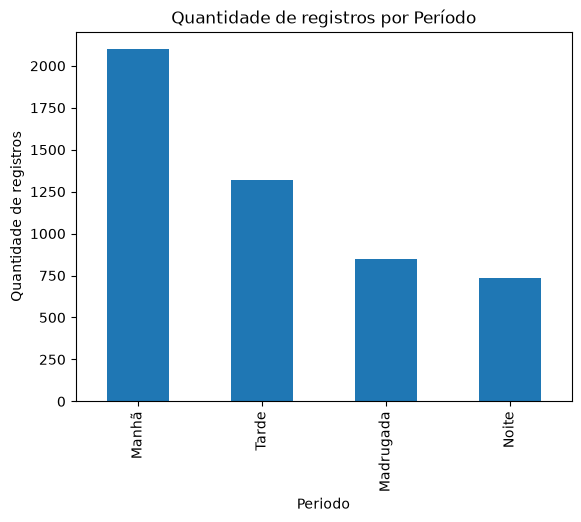

In [31]:
qtd_especies = dt.groupby('Periodo')['id_registro'].count().sort_values(ascending=False)
qtd_especies.plot(kind='bar')

plt.xlabel('Periodo')
plt.ylabel('Quantidade de registros')
plt.title('Quantidade de registros por Período')

plt.show()

### •Gráfico mais elaborado de qtd de registros por período

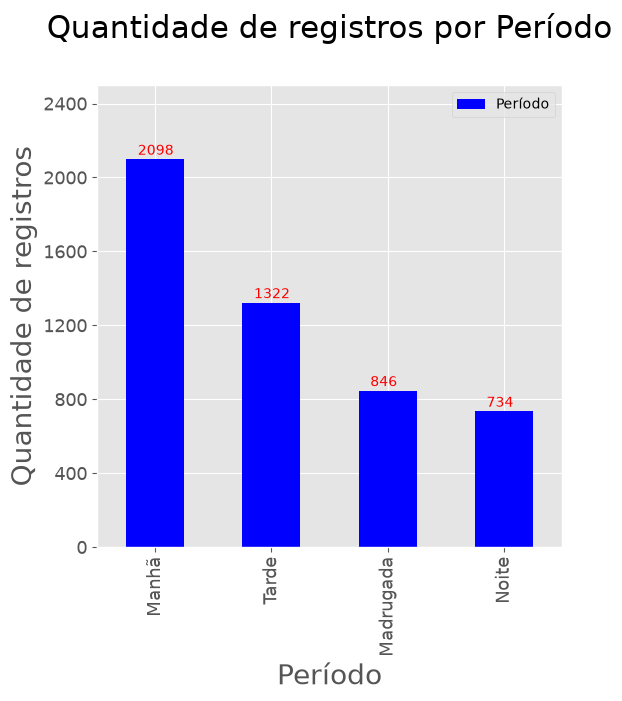

In [91]:
periodo = dt['Periodo'].value_counts()

ax = periodo.plot(
    kind='bar',
    rot=90, 
    figsize=(6,6),
    color='b',
    fontsize=13,
    label='Período'
    )
ax.set_title('Quantidade de registros por Período\n', fontsize=22, color='black')
ax.set_ylabel('Quantidade de registros', fontsize=20)
ax.set_xlabel('Período', fontsize=20)
ax.set_yticks([0,400,800,1200,1600,2000,2400])
ax.set_ylim((0,2500))

totals = []
total = sum(totals)
for i in ax.patches:
    ax.text(
        i.get_x() + 0.1, 
        i.get_height()+25,
        i.get_height(), 
        color='red'
    )
plt.style.use('ggplot')
plt.legend()
plt.show()